In [2]:
import os
import random
import numpy as np
import pandas as pd

import torch
import torchvision.transforms.functional as TF
from torch.utils.data import DataLoader
import torch.nn as nn
import importlib

from PIL import Image
from tqdm import tqdm
import torchvision.transforms.functional as TF
import cv2

# Custom Imports
from src.utils import Utils, AnalisiPredizioni
from src.loss import *
from src.config import Config
from src.trainer_gemini import Trainer
from src.unet import AttentionUNet, PlainUNet
from src.evaluator import Evaluator
from src.dataset_builder import DatasetBuilder, Dataset
from src.preprocessing import JointTransform, InpaintingDataset


In [8]:
# salviamo i risultati da plottare
eval_res = {}
test_loaders = []
model = AttentionUNet()

BASE_DIR = Config.BASE_DIR
IMAGE_SIZE = Config.IMAGE_SIZE
cfg = Config()
cfg.CACHE_DIR = f"{BASE_DIR}/dataset/cache_bagel_ex1_{IMAGE_SIZE}"
cfg.MANIFEST_OUT = f"{BASE_DIR}/dataset/manifest_split_bagel_ex1.csv"

#for element in ["bagel", "flux", "sensenova"]:
for element in ["bagel"]:
    checkpoint_path = f"/workspace/inpainting-unet-tesi/outputs/checkpoints/Unet_Att_{element}_exp1_best.pt"
    state_dict = torch.load(checkpoint_path, map_location=cfg.DEVICE)
    model.load_state_dict(state_dict)
    model.to(cfg.DEVICE)
    model.eval()

    manifest =pd.read_csv(f"/workspace/inpainting-unet-tesi/dataset/manifest_split_{element}_ex1.csv")
    test_ds = InpaintingDataset(manifest_df=manifest, split="test", transform=JointTransform(cfg.IMAGE_SIZE, train=False), cache_dir=f"/workspace/inpainting-unet-tesi/dataset/cache_{element}_ex1_256")
    test_loader = DataLoader(test_ds, batch_size=cfg.BATCH_SIZE, shuffle=False, num_workers=cfg.NUM_WORKERS, pin_memory=True)
    test_loaders.append((test_loader, element))

for test_loader, name_test in test_loaders:
    cfg.SEG_THRESHOLD = 0.5515
    evaluator = Evaluator(model, cfg)
    eval_res[f"UNet_Att_{name_test}"] = evaluator.evaluate(test_loader, postprocess=True)

/tmp/ipykernel_55110/2000726687.py:15: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(checkpoint_path, map_location=cfg.DEVICE)


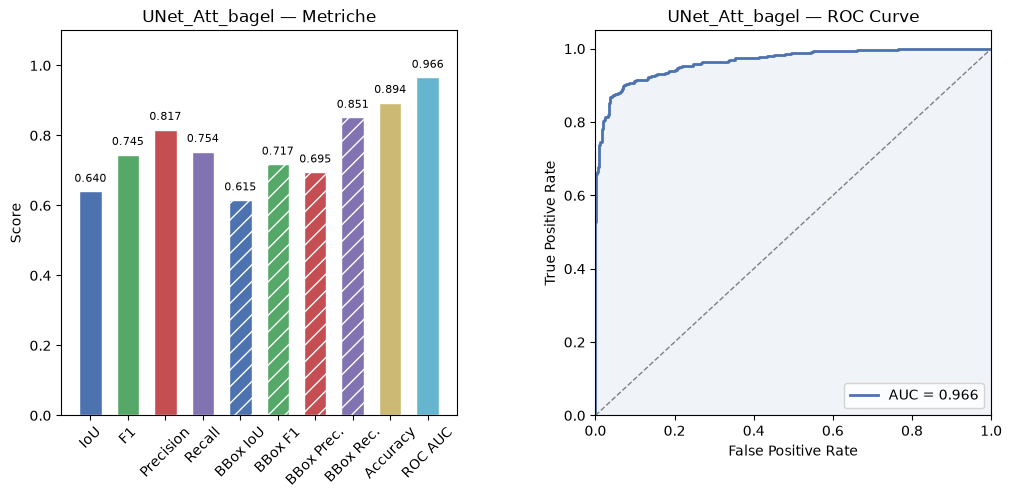

In [9]:
for name, results in eval_res.items():
  Utils.plot_metrics(results, name, cfg)

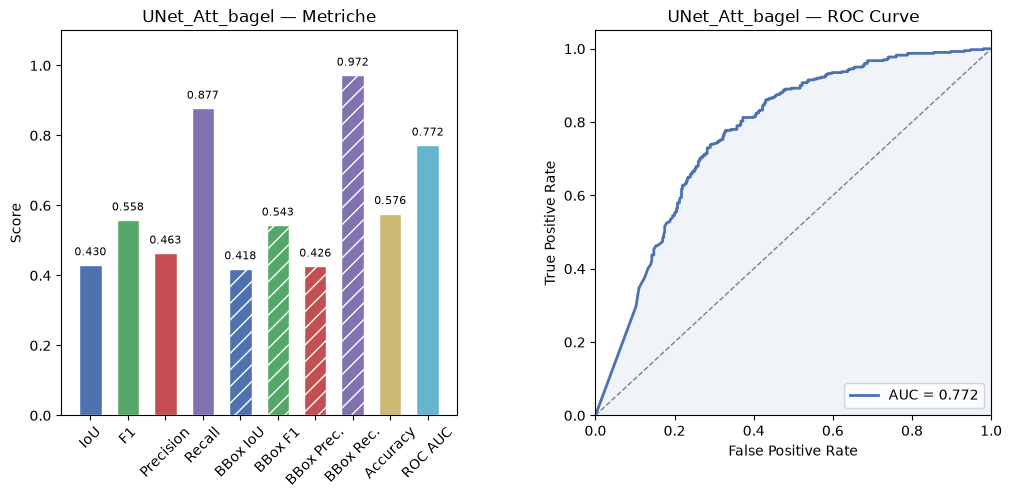

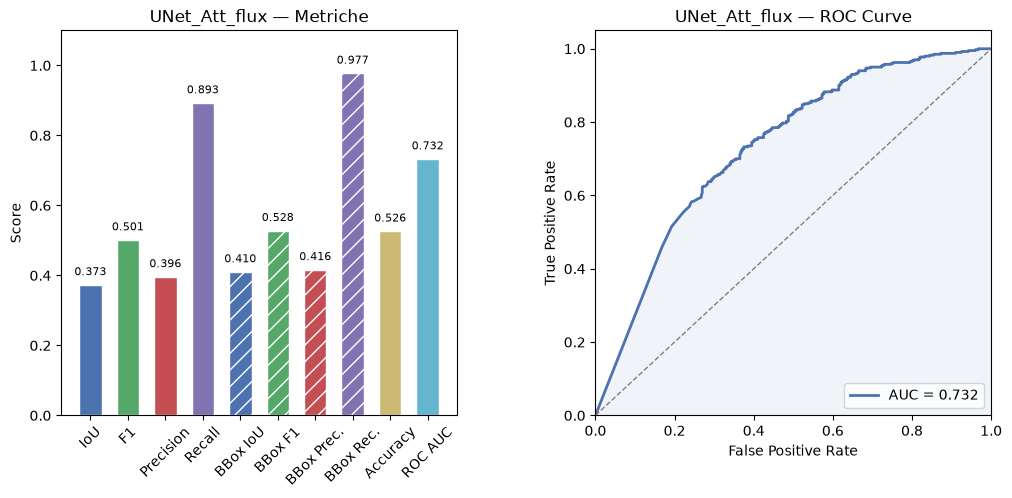

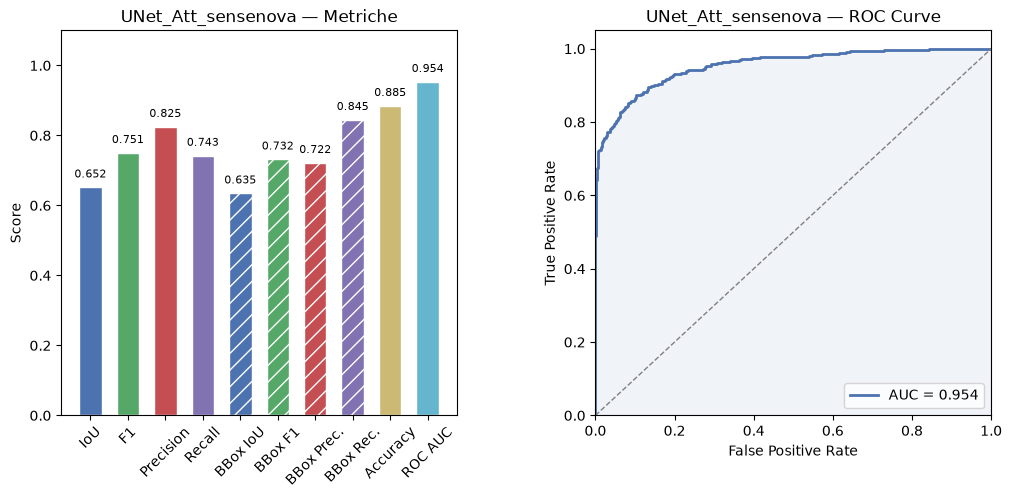

In [18]:
for name, results in eval_res.items():
  Utils.plot_metrics(results, name, cfg)

In [25]:
print(eval_res.keys())

dict_keys(['UNet_Att_bagel', 'UNet_Att_flux', 'UNet_Att_sensenova'])


In [29]:
import importlib
import src.utils

# 1. Ricarica il modulo su disco
importlib.reload(src.utils)

# 2. Re-importa gli oggetti aggiornati
from src.utils import Utils, AnalisiPredizioni


--- Conteggi ---
  TP: 395 | TN: 66 | FP: 334 | FN: 5


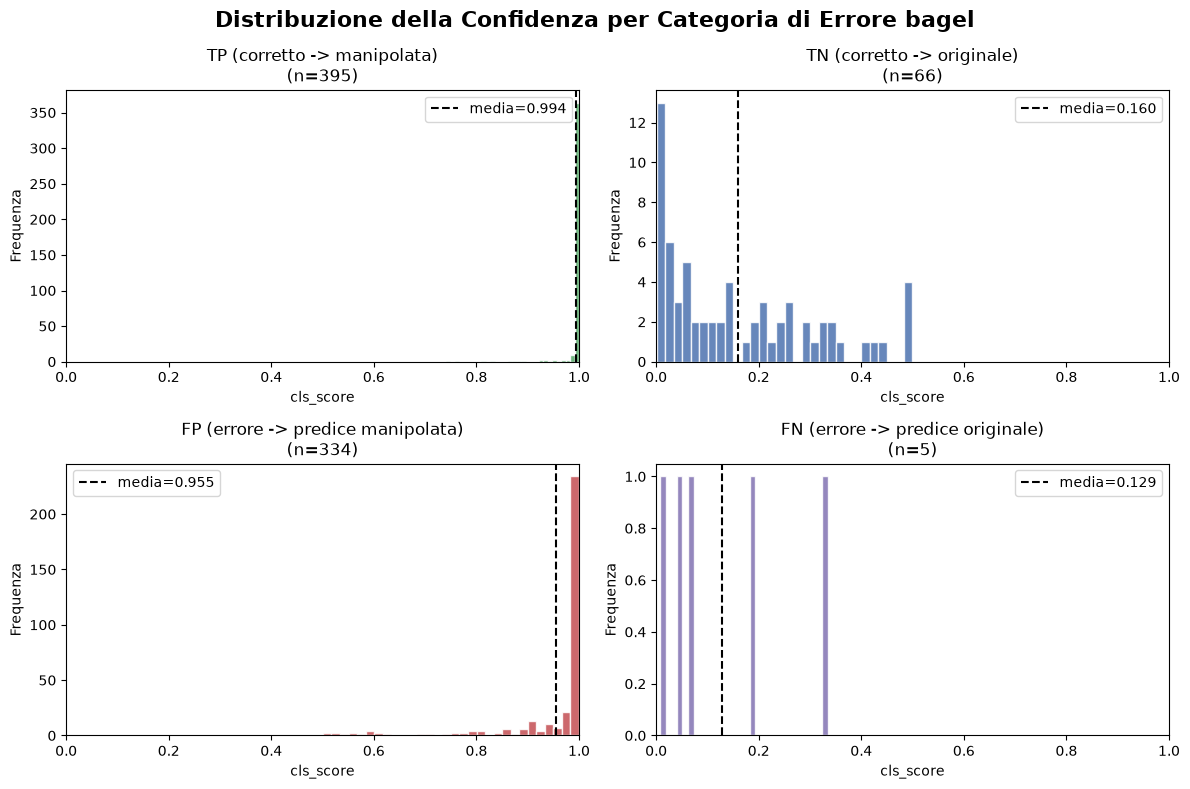


--- Conteggi ---
  TP: 398 | TN: 23 | FP: 377 | FN: 2


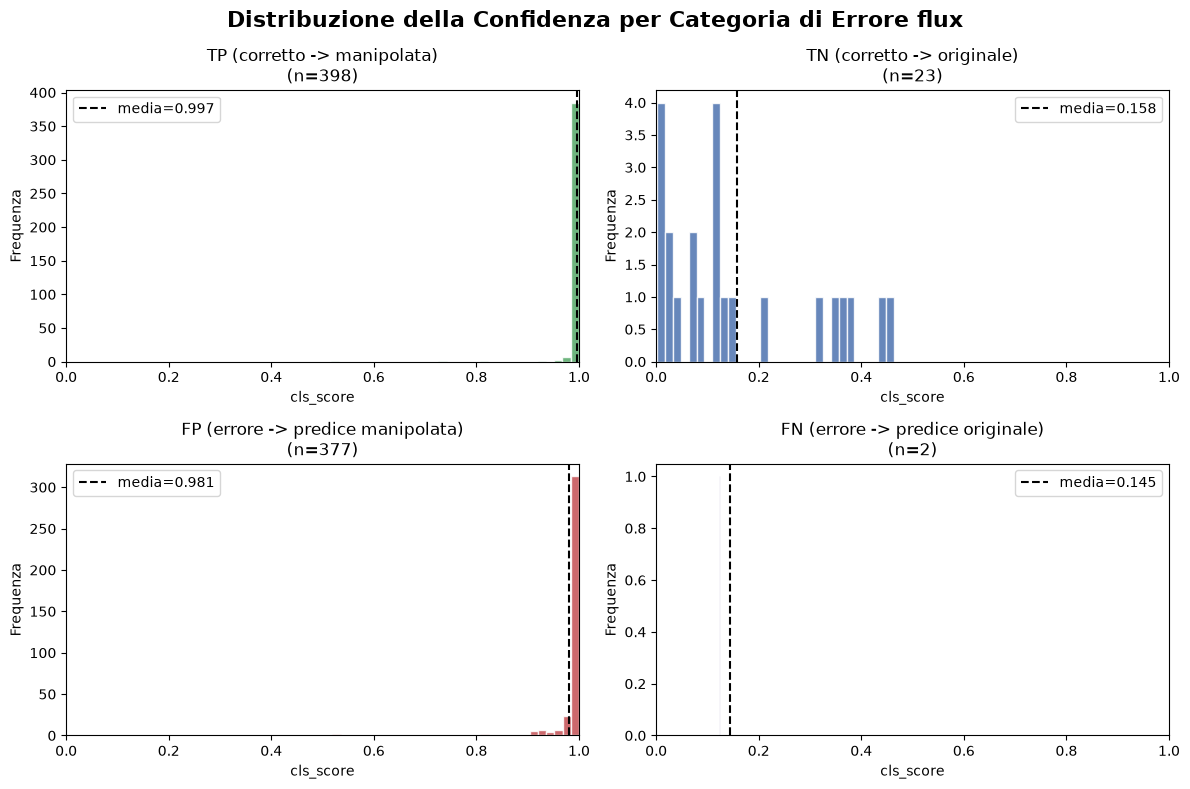


--- Conteggi ---
  TP: 341 | TN: 367 | FP: 33 | FN: 59


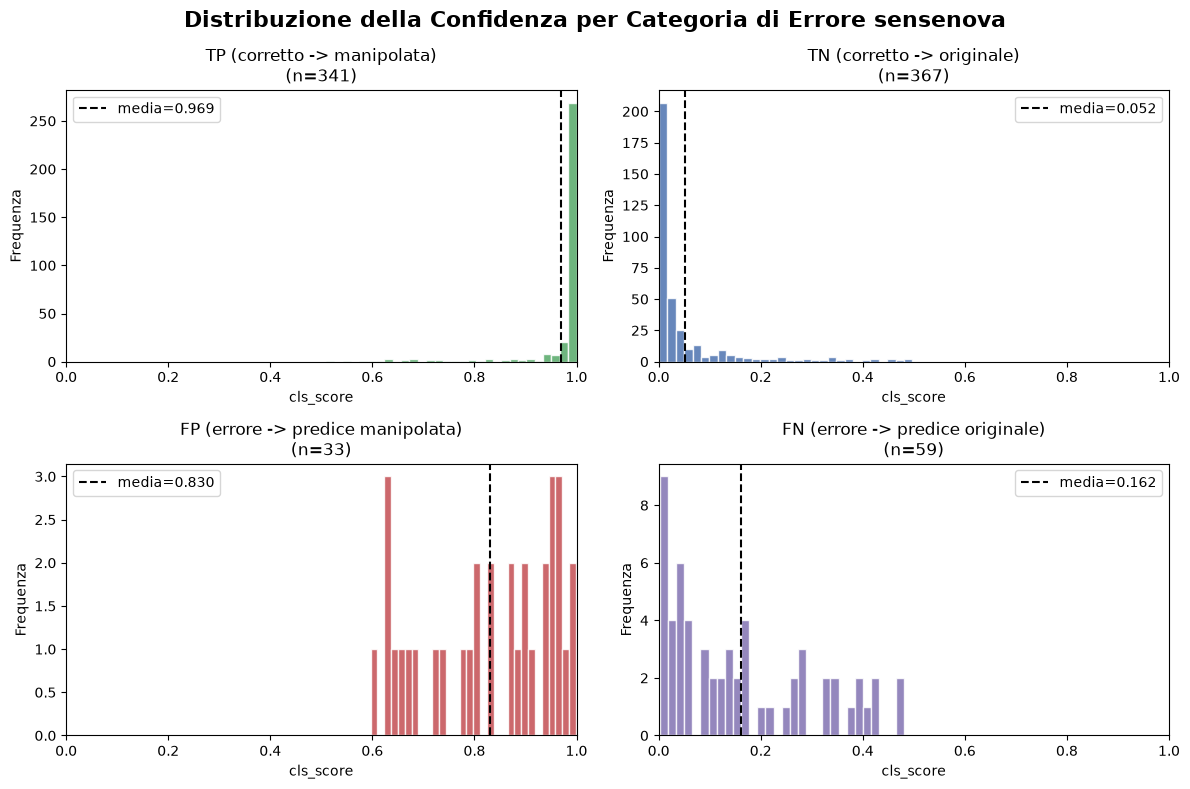

In [30]:
for element in ["bagel", "flux", "sensenova"]:
    AnalisiPredizioni.plot_confidence_vs_errors(results=eval_res[f"UNet_Att_{element}"], exp_name=element, cfg=cfg)

In [ ]:
cfg = Config()
cfg.NUM_WORKERS = 0
cfg.SEG_THRESHOLD = 0.5515

model = AttentionUNet()
checkpoint_path = "/workspace/inpainting-unet-tesi/outputs/checkpoints/Unet_Att_Synt_hd_painter_no_comp_att_best.pt"
state_dict = torch.load(checkpoint_path, map_location=cfg.DEVICE)
model.load_state_dict(state_dict)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.device_count() > 1:
    print(f"Utilizzo di {torch.cuda.device_count()} GPU abilitato.")
    model = nn.DataParallel(model)
    
model = model.to(device)
evaluator = Evaluator(model, cfg)

/tmp/ipykernel_3707913/4081289861.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(checkpoint_path, map_location=cfg.DEVICE)


In [3]:
manifest = pd.read_csv(cfg.MANIFEST_OUT)

val_ds = InpaintingDataset(manifest, "val", JointTransform(cfg.IMAGE_SIZE, train=False))
val_loader = DataLoader(val_ds, batch_size=cfg.BATCH_SIZE, shuffle=False, num_workers=cfg.NUM_WORKERS)

                           
test_ds = InpaintingDataset(manifest, "test", JointTransform(cfg.IMAGE_SIZE, train=False))
test_loader = DataLoader(test_ds, batch_size=cfg.BATCH_SIZE, shuffle=False, num_workers=cfg.NUM_WORKERS)

In [6]:
# evaluator.find_best_threshold(val_loader)

  threshold=0.10 → mean_f1=0.6037
  threshold=0.15 → mean_f1=0.6149
  threshold=0.20 → mean_f1=0.6213
  threshold=0.25 → mean_f1=0.6254
  threshold=0.30 → mean_f1=0.6284
  threshold=0.35 → mean_f1=0.6306
  threshold=0.40 → mean_f1=0.6324
  threshold=0.45 → mean_f1=0.6340
  threshold=0.50 → mean_f1=0.6352
  threshold=0.55 → mean_f1=0.6362
  threshold=0.60 → mean_f1=0.6370
  threshold=0.65 → mean_f1=0.6375
  threshold=0.70 → mean_f1=0.6377
  threshold=0.75 → mean_f1=0.6372
  threshold=0.80 → mean_f1=0.6356
  threshold=0.85 → mean_f1=0.6315
  threshold=0.90 → mean_f1=0.6212

Soglia ottimale: 0.70 - f1=0.6377


(np.float64(0.7000000000000002), 0.637684029629757)

In [9]:
res_raw = evaluator.evaluate_beta(test_loader, postprocess=False)
res_pp = evaluator.evaluate_beta(test_loader, postprocess=True)

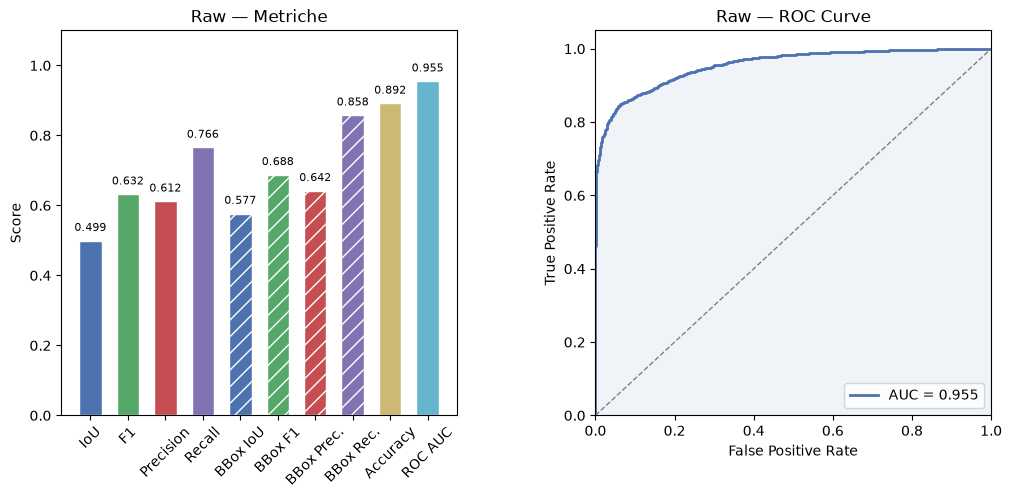

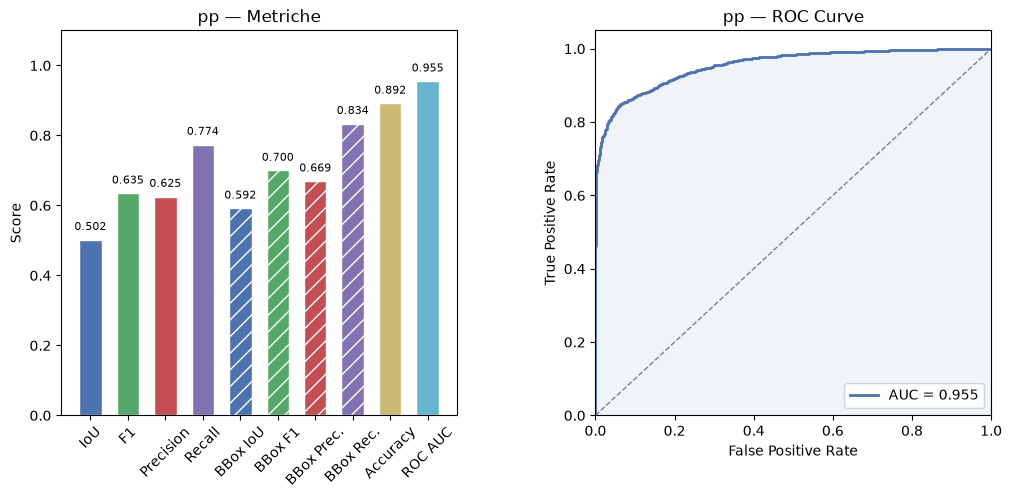

In [10]:
Utils.plot_metrics(res_raw, "Raw", cfg)
Utils.plot_metrics(res_pp, "pp", cfg)

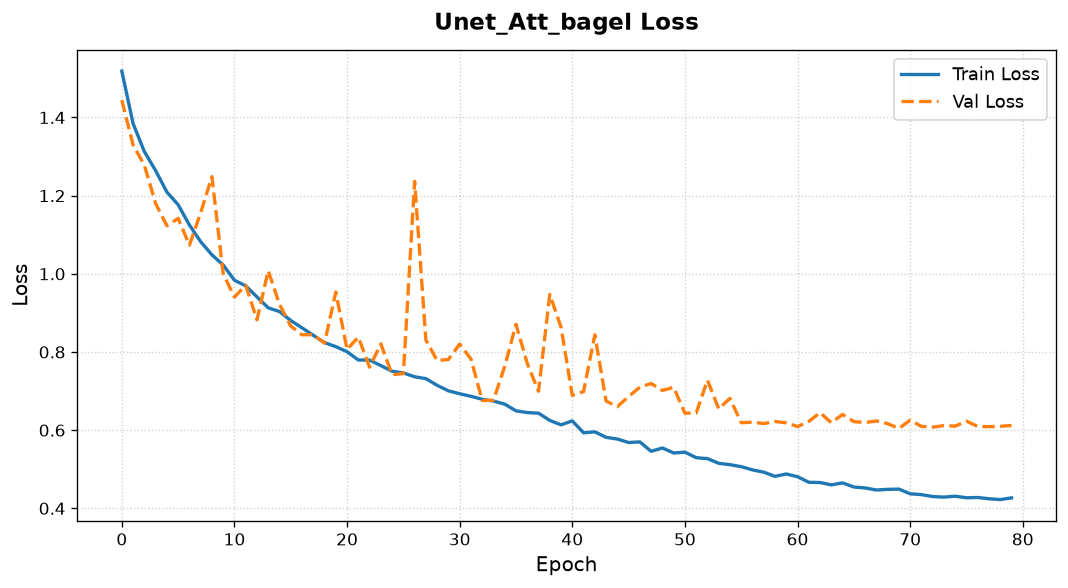

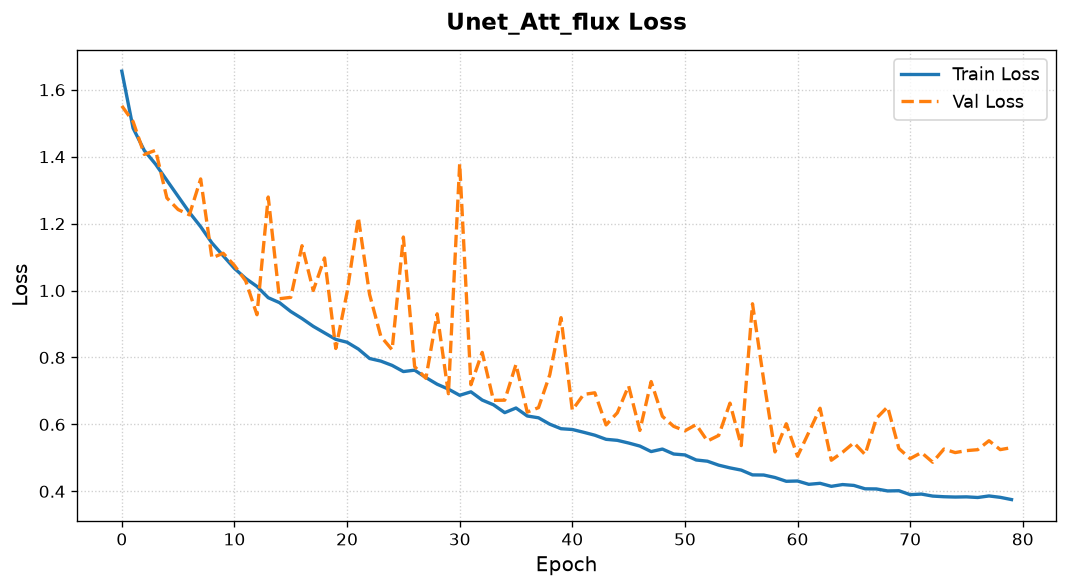

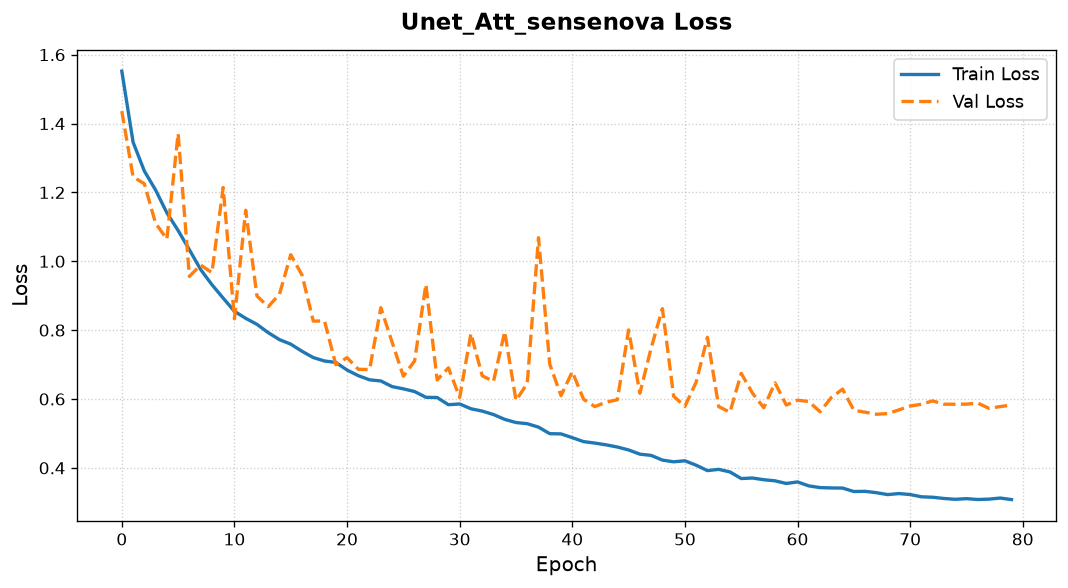

In [33]:
cfg = Config()

for element in ["bagel", "flux", "sensenova"]:
    Utils.plot_loss(model_name=f"Unet_Att_{element}", cfg=cfg)

In [11]:
import cv2
import numpy as np
import pandas as pd
from PIL import Image


def _load_mask(path) -> np.ndarray:
    """Maschera booleana (H, W) da .npy (qualsiasi dtype) o immagine."""
    if str(path).lower().endswith(".npy"):
        return np.squeeze(np.load(path)) > 0
    return np.asarray(Image.open(path).convert("L")) > 127


def _odd(x: float) -> int:
    x = max(3, int(round(x)))
    return x if x % 2 == 1 else x + 1


def _lap_abs(gray: Image.Image) -> np.ndarray:
    return np.abs(cv2.Laplacian(np.asarray(gray, np.float32), cv2.CV_32F))


def _hf_ratio(gray: Image.Image, mask: np.ndarray, border: int) -> float:
    """Energia HF media dentro la maschera / fuori dalla maschera.
    Si scartano i pixel vicino al bordo (erosione/dilatazione)."""
    k = np.ones((border, border), np.uint8)
    mu = mask.astype(np.uint8)
    inn = cv2.erode(mu, k) > 0
    out = cv2.dilate(mu, k) == 0
    if inn.sum() < 50 or out.sum() < 50:
        return np.nan
    lap = _lap_abs(gray)
    return float(lap[inn].mean() / (lap[out].mean() + 1e-6))


def _resize_mask(mask: np.ndarray, size_wh: tuple) -> np.ndarray:
    im = Image.fromarray(mask.astype(np.uint8) * 255)
    return np.asarray(im.resize(size_wh, Image.NEAREST)) > 127


def diagnose_scale(
    manifest: pd.DataFrame,
    n_per_group: int = 50,
    group_cols=("source", "inpainter"),
    target: int = 256,
    border: int = 9,
    seed: int = 42,
):
    """
    Per ogni gruppo (default: generatore x inpainter) campiona n righe del manifest e misura:
      - dimensioni di orig, manip, maschera e rapporto manip/orig
      - hf_native: energia HF dentro/fuori maschera a risoluzione nativa
      - hf_resized: lo stesso rapporto dopo il resize a `target` (come JointTransform)
      - glob_hf_orig / glob_hf_manip: energia HF media dell'intera immagine dopo il resize
        (se differiscono molto tra orig e manip c'e' una scorciatoia di scala per la classificazione)

    Lettura:
      - hf_native >> 1 e hf_resized -> ~1: il resize cancella la traccia localizzabile.
      - glob_hf_manip << glob_hf_orig: orig e manip hanno nitidezza globale diversa dopo il resize.

    Ritorna (df per riga, summary per gruppo).
    """
    cols = [c for c in group_cols if c in manifest.columns]
    missing = [c for c in group_cols if c not in manifest.columns]
    if missing:
        print(f"[diagnose_scale] colonne non presenti, ignorate: {missing}")
    if not cols:
        manifest = manifest.assign(_all="all")
        cols = ["_all"]

    records, n_err = [], 0
    for key, grp in manifest.groupby(cols):
        grp = grp.sample(n=min(n_per_group, len(grp)), random_state=seed)
        key = key if isinstance(key, tuple) else (key,)
        for _, row in grp.iterrows():
            try:
                o = Image.open(row["orig_path"]).convert("RGB")
                m = Image.open(row["manip_path"]).convert("RGB")
                mk = _load_mask(row["mask_path"])
                mask_shape = mk.shape  # (H, W) originale della maschera
                if mk.shape != (m.height, m.width):
                    mk = _resize_mask(mk, m.size)

                gm, go = m.convert("L"), o.convert("L")

                # nativo (bordo scalato con la risoluzione per confronto equo)
                b_nat = _odd(border * m.width / target)
                hf_nat = _hf_ratio(gm, mk, b_nat)

                # dopo il resize a target
                gm_t = gm.resize((target, target), Image.BILINEAR)
                go_t = go.resize((target, target), Image.BILINEAR)
                mk_t = _resize_mask(mk, (target, target))
                hf_res = _hf_ratio(gm_t, mk_t, border)

                records.append({
                    **dict(zip(cols, key)),
                    "image_id": row.get("image_id", ""),
                    "orig_w": o.width, "orig_h": o.height,
                    "manip_w": m.width, "manip_h": m.height,
                    "mask_h": mask_shape[0], "mask_w": mask_shape[1],
                    "scale_w": m.width / o.width,
                    "scale_h": m.height / o.height,
                    "mask_area_pct": 100 * mk.mean(),
                    "hf_native": hf_nat,
                    "hf_resized": hf_res,
                    "glob_hf_orig": float(_lap_abs(go_t).mean()),
                    "glob_hf_manip": float(_lap_abs(gm_t).mean()),
                })
            except Exception as e:
                n_err += 1
                print(f"[diagnose_scale] errore su {row.get('image_id', '?')}: {e}")

    df = pd.DataFrame(records)
    if df.empty:
        print("[diagnose_scale] nessun record valido.")
        return df, df
    df["glob_hf_ratio"] = df["glob_hf_manip"] / (df["glob_hf_orig"] + 1e-6)

    summary = df.groupby(cols).agg(
        n=("image_id", "size"),
        orig_size=("orig_w", lambda s: f"{int(s.median())}"),
        manip_size=("manip_w", lambda s: f"{int(s.median())}"),
        scale=("scale_w", "median"),
        mask_pct=("mask_area_pct", "median"),
        hf_native=("hf_native", "median"),
        hf_resized=("hf_resized", "median"),
        glob_hf_ratio=("glob_hf_ratio", "median"),
    ).round(3)

    print("\n=== Riepilogo per gruppo (mediane) ===")
    print(summary.to_string())

    # coerenza maschera: a quale delle due immagini corrisponde la sua shape
    same_manip = ((df["mask_w"] == df["manip_w"]) & (df["mask_h"] == df["manip_h"])).mean()
    same_orig = ((df["mask_w"] == df["orig_w"]) & (df["mask_h"] == df["orig_h"])).mean()
    print(f"\nMaschera = dimensioni manip: {same_manip:.0%} | = dimensioni orig: {same_orig:.0%}")
    print("Scale (manip/orig) valori distinti:",
          sorted(df["scale_w"].round(2).unique().tolist())[:10])
    if n_err:
        print(f"Righe con errori: {n_err}")
    return df, summary


# Uso:
manifest = pd.read_csv(cfg.MANIFEST_OUT)
df, summary = diagnose_scale(manifest, n_per_group=100)

[diagnose_scale] colonne non presenti, ignorate: ['inpainter']

=== Riepilogo per gruppo (mediane) ===
               n orig_size manip_size  scale  mask_pct  hf_native  hf_resized  glob_hf_ratio
source                                                                                      
BAGEL        100      1024       2048  2.000    18.453      4.249       1.702          0.982
SenseNovaU1  100      2048       2048  0.865    13.168      2.146       0.884          0.970
flux1-krea   100       768       2048  2.284    16.919      3.207       1.307          0.962

Maschera = dimensioni manip: 7% | = dimensioni orig: 100%
Scale (manip/orig) valori distinti: [0.82, 0.86, 1.0, 1.68, 1.78, 2.0, 2.28, 2.29, 2.46, 2.67]


In [13]:
import cv2
import numpy as np
import pandas as pd
from PIL import Image



FILTERS = {
    "bicubic": Image.BICUBIC,
    "bilinear": Image.BILINEAR,
    "lanczos": Image.LANCZOS,
}

def _load_mask(path) -> np.ndarray:
    """Maschera booleana (H, W) da .npy (qualsiasi dtype) o immagine."""
    if str(path).lower().endswith(".npy"):
        return np.squeeze(np.load(path)) > 0
    return np.asarray(Image.open(path).convert("L")) > 127


def _odd(x: float) -> int:
    x = max(3, int(round(x)))
    return x if x % 2 == 1 else x + 1


def _lap_abs(gray: Image.Image) -> np.ndarray:
    return np.abs(cv2.Laplacian(np.asarray(gray, np.float32), cv2.CV_32F))


def _hf_ratio(gray: Image.Image, mask: np.ndarray, border: int) -> float:
    """Energia HF media dentro la maschera / fuori dalla maschera.
    Si scartano i pixel vicino al bordo (erosione/dilatazione)."""
    k = np.ones((border, border), np.uint8)
    mu = mask.astype(np.uint8)
    inn = cv2.erode(mu, k) > 0
    out = cv2.dilate(mu, k) == 0
    if inn.sum() < 50 or out.sum() < 50:
        return np.nan
    lap = _lap_abs(gray)
    return float(lap[inn].mean() / (lap[out].mean() + 1e-6))


def _resize_mask(mask: np.ndarray, size_wh: tuple) -> np.ndarray:
    im = Image.fromarray(mask.astype(np.uint8) * 255)
    return np.asarray(im.resize(size_wh, Image.NEAREST)) > 127

def baseline_and_alignment(
    manifest: pd.DataFrame,
    n_per_group: int = 50,
    group_col: str = "source",
    tol: int = 2,
    margin: int = 15,
    target: int = 256,
    border: int = 9,
    seed: int = 42,
):
    """
    Tre controlli per generatore:

    1. Baseline HF: lo stesso rapporto HF dentro/fuori maschera calcolato sull'ORIGINALE.
       Misura quanto del rapporto dipende dal contenuto (oggetto texturato vs sfondo liscio).
       hf_excess = hf_manip / hf_orig: se ~1 la traccia non e' distinguibile dal contenuto.

    2. Allineamento: differenza tra le scale orizzontale e verticale (manip/orig).
       Se non e' ~0 l'aspect ratio cambia e maschera/immagine possono non coincidere.

    3. Fuori maschera: l'originale viene portato alla risoluzione di manip con vari filtri,
       e si misura la frazione di pixel che differisce (> tol) fuori dalla maschera dilatata
       di `margin` px. Il filtro con valore minimo e' quello usato dall'inpainter.
       Se resta alto con ogni filtro, fuori maschera non e' un semplice upscaling.
    """
    recs = []
    for key, grp in manifest.groupby(group_col):
        grp = grp.sample(n=min(n_per_group, len(grp)), random_state=seed)
        for _, r in grp.iterrows():
            try:
                o = Image.open(r["orig_path"]).convert("RGB")
                m = Image.open(r["manip_path"]).convert("RGB")
                mk_o = _load_mask(r["mask_path"])
                if mk_o.shape != (o.height, o.width):
                    mk_o = _resize_mask(mk_o, o.size)
                mk_m = _resize_mask(mk_o, m.size)

                hf_orig = _hf_ratio(o.convert("L"), mk_o, _odd(border * o.width / target))
                hf_man = _hf_ratio(m.convert("L"), mk_m, _odd(border * m.width / target))

                sw, sh = m.width / o.width, m.height / o.height
                rec = {
                    group_col: key,
                    "image_id": r.get("image_id", ""),
                    "hf_orig": hf_orig,
                    "hf_manip": hf_man,
                    "hf_excess": hf_man / hf_orig if hf_orig and not np.isnan(hf_orig) else np.nan,
                    "aspect_err": abs(sw - sh) / sw,
                }

                k = np.ones((margin, margin), np.uint8)
                outside = cv2.dilate(mk_m.astype(np.uint8), k) == 0
                ma = np.asarray(m).astype(np.int16)
                for name, f in FILTERS.items():
                    ou = np.asarray(o.resize(m.size, f)).astype(np.int16)
                    d = np.abs(ou - ma).max(axis=2)
                    rec[f"out_changed_{name}"] = float((d[outside] > tol).mean())
                    rec[f"out_mad_{name}"] = float(d[outside].mean())
                recs.append(rec)
            except Exception as e:
                print(f"[baseline] errore su {r.get('image_id', '?')}: {e}")

    df = pd.DataFrame(recs)
    if df.empty:
        print("[baseline] nessun record valido.")
        return df, df

    summary = df.drop(columns=["image_id"]).groupby(group_col).median().round(4)
    print("\n=== Mediane per gruppo ===")
    print(summary.T.to_string())
    return df, summary


# Uso:
#   from diagnose_baseline import baseline_and_alignment
df2, summ2 = baseline_and_alignment(manifest, n_per_group=50)


=== Mediane per gruppo ===
source                 BAGEL  SenseNovaU1  flux1-krea
hf_orig               2.0281       1.2621      1.2404
hf_manip              4.5692       2.6940      3.4265
hf_excess             2.1276       1.8472      2.4428
aspect_err            0.0000       0.0002      0.0000
out_changed_bicubic   0.0932       0.0914      0.0920
out_mad_bicubic       4.3526       5.1326      4.0629
out_changed_bilinear  0.1309       0.0977      0.1307
out_mad_bilinear      4.8947       5.5401      4.3704
out_changed_lanczos   0.1159       0.0923      0.1045
out_mad_lanczos       4.7023       5.3519      4.3259
